# Where a coding AI picks its algorithm

**Experiment 34 (iteration 7).** Model: bf16 **Qwen3-8B** (revision `b968826d`, thinking off, temperature 1). Question: *does one early generated token decide which algorithm the model writes, and do random activation pushes change the algorithm through that token or through a direction in the prompt states?*

Asked for connected components, the model almost always writes **union-find**. Asked for a weighted shortest path it writes **Dijkstra**, and asked for the k-th smallest element it **sorts**. A random push to the residual stream sometimes knocks it onto a different, still-correct algorithm (an *escape*, the closest this study gets to a "more creative" answer). The study pre-registered two explanations of *which* pushes escape:

- **F (early fork).** Prefix resampling found that on **T10** (connected components) the algorithm is fixed at generated tokens 10-11 of the opening `def solve(n, edges):`. In the resampled continuations, `' parent'` at token 10, or `' def'` then `' find'`, led to union-find. `' #'` or `' from'`, or `' def'` then `' dfs'`, led to a graph search. The label entropy given the token falls to 0 bits at token 11. The **fork margin `m`** is the teacher-forced log-odds that a pushed prompt puts on the off-default fork tokens. **T2** (Dijkstra) has no single early fork, so its pre-declared fallback margin is the 48-token opening log-likelihood ratio `llr48`.
- **P2 (prompt-state axis).** This is a difference-in-means direction from the default to the runner-up algorithm in the prompt states (forced-runner-up prompts minus their padding twins, at block `L_ax`). The predictor **`b`** is a push's projection on that axis, in units of the forced-prompt distance. It must beat three competitors computed from the same displacement: the energy share in the catalogue-centroid subspace (`pi_Pt`), the raw displacement norm (`norm`) and the energy share in the top-4 forced/ban difference directions (`a_share`).

Both hypotheses and their thresholds were hash-committed (a sha256 chain) before any outcome was opened. They were then tested on **40 equal-dose random directions per task** (alpha 2, blocks 12-23, task-spec positions). The outcome `y` of a direction is the share of its programs that are **correct and use a non-default catalogue algorithm**.

**What this notebook runs.** `method.py` orchestrates eight stages. All but the analysis stages need the 8B model on a GPU (about 1.7 GPU-hours on an RTX 4090). The notebook therefore shows the orchestrator unchanged, then **runs the pre-registered analysis stage** (`src/analysis7.py::f_and_p2` with `src/stats7.py`). It uses the committed predictors and outcomes of all 80 cells (dataset `p2_directions`, loaded from GitHub). It recomputes the committed verdicts, **F: NOT SUPPORTED (inconclusive)** and **P2: DISCONFIRMED**, and checks every number against the committed results.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (method.py logs with it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# method.py (the orchestrator)
import argparse
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# src/stats7.py and src/analysis7.py (the analysis stage this notebook runs)
import math
from collections import defaultdict
from typing import Any, Sequence

import numpy as np
from scipy import stats

# notebook additions: stand-ins for `import stats7 as S` / `import c7 as common`, and plotting
import types

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-7/experiment-34/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
META = data["metadata"]
EXAMPLES = data["datasets"][0]["examples"]
print(f"dataset {data['datasets'][0]['dataset']}: {len(EXAMPLES)} examples")
print(META["description"])
print("model:", META["model"])
print("first example (without the nested commit #3 record and fork-token probabilities):",
      {k: v for k, v in EXAMPLES[0].items() if k not in ("metadata_committed_predictors", "metadata_fork_token_probs")})

dataset p2_directions: 80 examples
Curated demo subset of art_pHL7LWNhpcCS (iteration 7, 'Does one early token decide the algorithm?'): dataset p2_directions of method_out.json, all 80 rows (40 random push directions x tasks T10, T2), joined with the full-precision committed predictors (commit #3b), the outcome counts (f_cells) and T10's fork-token probabilities.
model: Qwen/Qwen3-8B b968826d9c46dd6066d109eabc6255188de91218, bf16, thinking off
first example (without the nested commit #3 record and fork-token probabilities): {'input': 'task T10; fixed random direction rand_9101 pushed at alpha 2 (absolute ban unit, blocks 12-23, task-spec positions, prefill only)', 'output': '0', 'predict_axis': '-0.0274061', 'predict_pt': '0.000762404', 'predict_norm': '13.7551', 'predict_a_share': '0.000408064', 'predict_fork_margin': '-3.62118', 'predict_llr48': '-12.2841', 'metadata_task': 'T10', 'metadata_seed': 9101, 'metadata_attempted': 0.0, 'metadata_confirmed_escaper_exp29': False, 'metadata_c

## Configuration

The analysis has two resampling knobs. The original code hard-codes 10,000 for both, and at those values the whole analysis takes about 20 s on two CPU cores. Point estimates do not depend on them: Spearman, Kendall, AUC, tie ceilings and the layer profile come out the same at any size. Permutation p values, bootstrap CIs and paired differences reproduce the committed numbers exactly only at 10,000.

`RUN_FULL_PIPELINE` switches on the orchestrator in section 1. It needs the full repository and a GPU.

In [5]:
# Resampling sizes: the original values (10,000 each, hard-coded in src/analysis7.py and defaults in src/stats7.py)
N_PERM = 10000  # permutations per Spearman test (S.perm_p) and for the pooled within-task test (S.pooled_perm_p)
N_BOOT = 10000  # bootstrap resamples for the rho CIs (S.boot_ci) and the axis-vs-competitor differences (S.paired_boot_diff)

# The orchestrator (section 1). True re-runs method.py's stages: needs the repository's src/, .venv and Qwen3-8B on a GPU
RUN_FULL_PIPELINE = False
STAGES = "all"  # method.py --stages: "all" or a comma list of stage0,forks,axis,freeze,predict,push,analysis,outputs

## 1. The orchestrator: `method.py`

`method.py` runs every stage in the committed order. Each GPU stage runs as its own process, so only one bf16 Qwen3-8B is on the GPU at a time. Every stage resumes from row keys and commit files.

| stage | script | what it does | hardware |
|---|---|---|---|
| `stage0` | `src/stage0.py` | engine check against the earlier runs exp29 and exp30, GPU unit tests; starts the label worker | GPU |
| `forks` | `src/forkrun.py` | prefix resampling of 48 base paths, change points against a permutation null, fork tokens → commit #1 (#1b, #1c) | GPU |
| `axis` | `src/axis7.py` | default-to-runner-up axis, `P_t`, `U4` → commit #2 | GPU |
| `freeze` | `src/make_commit0b.py` | analysis code frozen by hash before commit #3 | CPU |
| `predict` | `src/predict7.py` | teacher-forced margins, opening LLRs, axis projections and competitors → commit #3 (#3b) | GPU |
| `push` | `run_after_c3.sh` and exploratory scripts | sealed-row labelling, T03 confirmation, targeted push, top-five push, re-measurement, clamp | GPU |
| `analysis` | `src/analysis7.py` … `src/figures7.py` | **pre-registered F/P2 analysis (run below)**, tests, geometry, figures | CPU |
| `outputs` | `src/outputs7.py`, `audit/rederive.py` | `method_out.json`, standard-library re-derivation | CPU |

The next cell is `method.py` unchanged except for three notebook fixes, marked `# notebook:`, and its imports, which moved to the imports cell. `ROOT` is the working directory, because a notebook has no `__file__`. `main()` takes the stage list as an argument instead of parsing `--stages`. The `__main__` guard becomes `if RUN_FULL_PIPELINE`. The cell only *defines* the orchestrator. Running it needs the repository's `src/` tree, its `.venv` and the 8B model on a GPU, so it runs only when `RUN_FULL_PIPELINE = True`.

In [6]:
"""Iteration 7 (direction 3): does one early token decide the algorithm? Orchestrator of every stage, in the
committed order. Each GPU stage is a separate process (one bf16 Qwen3-8B on the GPU at a time); every stage is
resumable (row keys / commit files), so re-running skips finished work.

Stages (comma list or 'all'):
  stage0    src/stage0.py         Stage 0 engine check + GPU unit tests; starts the label worker
  forks     src/forkrun.py        F1 prefix resampling, change points, forks -> commit #1 (amendments #1b/#1c)
  axis      src/axis7.py          P2 axis -> commit #2
  freeze    src/make_commit0b.py  analysis code frozen by hash (before commit #3)
  predict   src/predict7.py       predictors, margins, LLR -> commit #3 (#3b)
  push      run_after_c3.sh       sealed-row labelling, F/P2 analysis, clamp selection, T03 confirmation, targeted
                                  push, top-five push, same-engine re-measurement, clamp (GPU)
  analysis  analysis7 / tests / top5geo / analysis_push / novelty / figures
  outputs   src/outputs7.py + audit/rederive.py -> method_out.json
"""

ROOT = Path.cwd()  # notebook: was Path(__file__).resolve().parent (a notebook has no __file__)
PY = str(ROOT / ".venv" / "bin" / "python")
LOGS = ROOT / "logs"
LOGS.mkdir(exist_ok=True)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(str(LOGS / "method.log"), rotation="30 MB", level="DEBUG")


def run(args: list[str], log: str, check: bool = True) -> int:
    t0 = time.time()
    logger.info(f"run {' '.join(args)} -> logs/{log}")
    with open(LOGS / log, "a") as f:
        p = subprocess.Popen(args, cwd=ROOT, stdout=f, stderr=subprocess.STDOUT)
        rc = p.wait()
    logger.info(f"exit {rc} after {time.time() - t0:.0f}s")
    if check and rc != 0:
        raise RuntimeError(f"{args} failed with exit code {rc}")
    return rc


def start_labeller(raw: str = "data/samples_raw.jsonl", labels: str = "data/labels.jsonl",
                   log: str = "label7.out") -> subprocess.Popen:
    f = open(LOGS / log, "a")
    p = subprocess.Popen([PY, "src/label7.py", raw, labels], cwd=ROOT, stdout=f, stderr=subprocess.STDOUT)
    logger.info(f"label worker pid {p.pid} ({raw})")
    return p


def wait_labels(raw: str, labels: str, timeout: float = 1800) -> None:
    """Block until every row of `raw` has a label row (the follow-mode worker catches up)."""
    sys.path.insert(0, str(ROOT / "src"))
    from c7 import read_jsonl
    t0 = time.time()
    while time.time() - t0 < timeout:
        n_raw = len(read_jsonl(ROOT / raw))
        n_lab = len(read_jsonl(ROOT / labels))
        if n_lab >= n_raw:
            return
        time.sleep(10)
    logger.warning(f"labelling of {raw} incomplete after {timeout}s")


@logger.catch(reraise=True)
def main(stages_arg: str = "all") -> None:
    # notebook: was ap = argparse.ArgumentParser(); ap.add_argument("--stages", default="all"); args = ap.parse_args()
    args = argparse.Namespace(stages=stages_arg)
    order = ["stage0", "forks", "axis", "freeze", "predict", "push", "analysis", "outputs"]
    stages = order if args.stages == "all" else args.stages.split(",")
    lab = None
    if any(s in stages for s in ("stage0", "push")):
        lab = start_labeller()
    try:
        if "stage0" in stages:
            run([PY, "src/make_commit0.py"], "commit0.out", check=False) if not (ROOT / "predictions" /
                                                                               "commit0.json").exists() else None
            run([PY, "src/stage0.py"], "stage0.out")
        if "forks" in stages:
            run([PY, "src/forkrun.py", "--paths", "6", "--tasks", "T2,T10,T03", "--define"], "forkrun.out")
        if "axis" in stages and not (ROOT / "predictions" / "commit2_axis.json").exists():
            run([PY, "src/axis7.py"], "axis7.out")
        if "freeze" in stages and not (ROOT / "predictions" / "commit0b_analysis_code.json").exists():
            run([PY, "src/make_commit0b.py"], "commit0b.out")
        if "predict" in stages and not (ROOT / "predictions" / "commit3_predictors.json").exists():
            run([PY, "src/predict7.py", "--tiers", "1,2,3"], "predict7.out")
        if "push" in stages:
            run(["bash", "run_after_c3.sh"], "run_after_c3.out", check=False)
            pid = int((LOGS / "pushrun.pid").read_text())
            while Path(f"/proc/{pid}").exists():
                time.sleep(15)
            run([PY, "src/pushrun.py", "targeted_ext", "--deadline-min", "30"], "pushrun_ext.out", check=False)
            run([PY, "src/explore_llr.py"], "explore_llr.out", check=False)        # exploratory, post hoc
            run([PY, "src/force_token.py"], "force_token.out", check=False)        # exploratory, post hoc
            run([PY, "src/label7.py", "--once", "data/samples_raw_force.jsonl", "data/labels_force.jsonl"],
                "label7_force.out", check=False)
            run([PY, "src/fork_probs.py"], "fork_probs.out", check=False)          # audit support (T10 token probs)
        if "analysis" in stages:
            wait_labels("data/samples_raw.jsonl", "data/labels.jsonl")
            run([PY, "src/label7.py", "--once", "data/samples_raw_s0b.jsonl", "data/labels_s0b.jsonl"],
                "label7_s0b_once.out", check=False)
            run([PY, "src/label7.py", "--once", "data/samples_raw_clamp.jsonl", "data/labels_clamp.jsonl"],
                "label7_clamp.out", check=False)
            run([PY, "src/analysis7.py"], "analysis7.out")
            run([PY, "src/tests_cpu.py"], "tests_cpu.out", check=False)
            run([PY, "src/top5geo.py"], "top5geo.out", check=False)
            run([PY, "src/analysis_push.py"], "analysis_push.out")
            run([PY, "src/analysis_force.py"], "analysis_force.out", check=False)
            run([PY, "src/summary7.py"], "summary7.out", check=False)
            run([PY, "src/novelty7.py"], "novelty7.out", check=False)
            run([PY, "src/figures7.py"], "figures7.out", check=False)
        if "outputs" in stages:
            run([PY, "src/outputs7.py"], "outputs7.out")
            run([PY, "audit/rederive.py"], "rederive.out", check=False)
            run([PY, "src/readme7.py"], "readme7.out", check=False)
    finally:
        if lab is not None:
            (ROOT / "data" / "STOP_LABELLER").touch()
            lab.wait(timeout=600)


if RUN_FULL_PIPELINE:  # notebook: was `if __name__ == "__main__": main()`
    main(STAGES)
else:
    logger.info("method.py defined; its GPU stages are not launched (RUN_FULL_PIPELINE = False). The analysis "
                "stage (src/analysis7.py) runs below on the committed predictors and outcomes.")

17:00:10|INFO   |method.py defined; its GPU stages are not launched (RUN_FULL_PIPELINE = False). The analysis stage (src/analysis7.py) runs below on the committed predictors and outcomes.


## 2. Statistics toolkit: `src/stats7.py`

This module is copied unchanged and uses numpy and scipy only. Every rank statistic in the study goes through it:

- `spearman` computes the rank correlation. It skips NaN pairs and returns NaN when either vector is constant.
- `perm_p` gives a one-sided permutation p for Spearman over `n` permutations of standardised ranks. Its floor is `1/(n+1)`, so about 1e-4 at n = 10,000.
- `tie_ceiling` gives the best Spearman that any untied predictor could reach given the ties in `y`. Many directions have `y = 0`, so the ceiling is below 1.
- `boot_ci` and `paired_boot_diff` give percentile bootstrap CIs for rho, and for rho(axis) − rho(competitor) over resampled directions.
- `pooled_within` and `pooled_perm_p` compute the Pearson correlation of within-task ranks scaled to [0, 1], with a permutation test.
- `auc`, `kendall` and `holm` are used here. `glm_fit` / `calibration` (binomial GLM with held-out MAE), `mcnemar_exact`, `binom_greater`, `fisher_exact` and `logit` serve the other stages.

The `S` namespace at the end stands in for `import stats7 as S`, so the analysis code runs unchanged.

In [7]:
# ---------------------------------------------------------------------------- src/stats7.py (verbatim)
"""Statistics for iteration 7 (numpy/scipy only): Spearman with permutation p and bootstrap CIs, the tie ceiling,
pooled within-task rank correlation, paired bootstrap of rho differences, binomial-GLM calibration with held-out
MAE, AUC, exact McNemar, exact binomial, Holm."""


def ranks(x: Sequence[float]) -> np.ndarray:
    return stats.rankdata(np.asarray(x, dtype=float), method="average")


def spearman(x: Sequence[float], y: Sequence[float]) -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = ~(np.isnan(x) | np.isnan(y))
    x, y = x[ok], y[ok]
    if len(x) < 3 or np.ptp(x) == 0 or np.ptp(y) == 0:
        return float("nan")
    rx, ry = ranks(x), ranks(y)
    return float(np.corrcoef(rx, ry)[0, 1])


def perm_p(x: Sequence[float], y: Sequence[float], n: int = 10000, seed: int = 0,
           alternative: str = "greater") -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = ~(np.isnan(x) | np.isnan(y))
    x, y = x[ok], y[ok]
    obs = spearman(x, y)
    if obs != obs:
        return float("nan")
    rx, ry = ranks(x), ranks(y)
    rx = (rx - rx.mean()) / rx.std()
    ry = (ry - ry.mean()) / ry.std()
    rng = np.random.default_rng(seed)
    null = np.array([np.mean(rx * ry[rng.permutation(len(ry))]) for _ in range(n)])
    if alternative == "greater":
        return float((1 + np.sum(null >= obs - 1e-12)) / (1 + n))
    if alternative == "less":
        return float((1 + np.sum(null <= obs + 1e-12)) / (1 + n))
    return float((1 + np.sum(np.abs(null) >= abs(obs) - 1e-12)) / (1 + n))


def tie_ceiling(y: Sequence[float]) -> float:
    """Spearman of y with a perfectly concordant untied predictor (ties of y broken arbitrarily)."""
    y = np.asarray(y, float)
    y = y[~np.isnan(y)]
    if len(y) < 3 or np.ptp(y) == 0:
        return float("nan")
    x = stats.rankdata(y, method="ordinal")
    return spearman(x, y)


def kendall(x: Sequence[float], y: Sequence[float]) -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = ~(np.isnan(x) | np.isnan(y))
    if ok.sum() < 3:
        return float("nan")
    return float(stats.kendalltau(x[ok], y[ok]).statistic)


def boot_ci(x: Sequence[float], y: Sequence[float], n: int = 10000, seed: int = 1) -> tuple[float, float]:
    x, y = np.asarray(x, float), np.asarray(y, float)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(x), len(x))
        r = spearman(x[i], y[i])
        if r == r:
            vals.append(r)
    if not vals:
        return (float("nan"), float("nan"))
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5)))


def paired_boot_diff(xa: Sequence[float], xb: Sequence[float], y: Sequence[float], n: int = 10000,
                     seed: int = 2) -> dict[str, float]:
    """rho(xa, y) - rho(xb, y) over direction resamples; 95% percentile CI."""
    xa, xb, y = np.asarray(xa, float), np.asarray(xb, float), np.asarray(y, float)
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        ra, rb = spearman(xa[i], y[i]), spearman(xb[i], y[i])
        if ra == ra and rb == rb:
            d.append(ra - rb)
    obs = spearman(xa, y) - spearman(xb, y)
    if not d:
        return {"diff": obs, "lo": float("nan"), "hi": float("nan"), "n_valid": 0}
    return {"diff": obs, "lo": float(np.percentile(d, 2.5)), "hi": float(np.percentile(d, 97.5)), "n_valid": len(d)}


def pooled_within(groups: list[tuple[Sequence[float], Sequence[float]]]) -> float:
    """Pearson correlation of within-task ranks (each task ranked separately, ranks scaled to [0, 1])."""
    xs, ys = [], []
    for x, y in groups:
        x, y = np.asarray(x, float), np.asarray(y, float)
        ok = ~(np.isnan(x) | np.isnan(y))
        x, y = x[ok], y[ok]
        if len(x) < 3:
            continue
        xs.append((ranks(x) - 1) / (len(x) - 1))
        ys.append((ranks(y) - 1) / (len(y) - 1))
    if not xs:
        return float("nan")
    X, Y = np.concatenate(xs), np.concatenate(ys)
    if np.ptp(X) == 0 or np.ptp(Y) == 0:
        return float("nan")
    return float(np.corrcoef(X, Y)[0, 1])


def pooled_perm_p(groups: list[tuple[Sequence[float], Sequence[float]]], n: int = 10000, seed: int = 3) -> float:
    obs = pooled_within(groups)
    rng = np.random.default_rng(seed)
    cnt = 0
    for _ in range(n):
        g2 = [(x, np.asarray(y)[rng.permutation(len(y))]) for x, y in groups]
        cnt += pooled_within(g2) >= obs - 1e-12
    return float((1 + cnt) / (1 + n))


def auc(score: Sequence[float], label: Sequence[int]) -> float:
    s, l = np.asarray(score, float), np.asarray(label, int)
    pos, neg = s[l == 1], s[l == 0]
    if len(pos) == 0 or len(neg) == 0:
        return float("nan")
    u = stats.mannwhitneyu(pos, neg, alternative="two-sided").statistic
    return float(u / (len(pos) * len(neg)))


def glm_fit(m: np.ndarray, k: np.ndarray, n: np.ndarray) -> tuple[float, float]:
    """Binomial GLM k ~ Bin(n, sigmoid(b0 + b1 m)) by Newton-Raphson (ridge 1e-6)."""
    X = np.column_stack([np.ones_like(m), m])
    b = np.zeros(2)
    for _ in range(100):
        p = 1 / (1 + np.exp(-(X @ b)))
        W = n * p * (1 - p)
        g = X.T @ (k - n * p)
        Hm = X.T @ (X * W[:, None]) + 1e-6 * np.eye(2)
        step = np.linalg.solve(Hm, g)
        b = b + step
        if np.abs(step).max() < 1e-10:
            break
    return float(b[0]), float(b[1])


def calibration(m: Sequence[float], k: Sequence[int], n: Sequence[int], strata: Sequence[str], n_splits: int = 10,
                seed: int = 4) -> dict[str, Any]:
    """Held-out MAE of the binomial-GLM fit over random half-splits stratified by `strata`."""
    m, k, n = np.asarray(m, float), np.asarray(k, float), np.asarray(n, float)
    strata = np.asarray(strata)
    ok = ~np.isnan(m)
    m, k, n, strata = m[ok], k[ok], n[ok], strata[ok]
    b0, b1 = glm_fit(m, k, n)
    rng = np.random.default_rng(seed)
    maes = []
    for _ in range(n_splits):
        tr = np.zeros(len(m), bool)
        for s in np.unique(strata):
            idx = np.where(strata == s)[0]
            idx = idx[rng.permutation(len(idx))]
            tr[idx[: (len(idx) + 1) // 2]] = True
        if tr.all() or (~tr).all():
            continue
        c0, c1 = glm_fit(m[tr], k[tr], n[tr])
        p = 1 / (1 + np.exp(-(c0 + c1 * m[~tr])))
        maes.append(float(np.mean(np.abs(p - k[~tr] / n[~tr]))))
    return {"b0": b0, "b1": b1, "mae_heldout_mean": float(np.mean(maes)) if maes else float("nan"),
            "mae_heldout_splits": maes, "n_cells": int(len(m))}


def mcnemar_exact(b: int, c: int) -> float:
    """Two-sided exact McNemar on discordant counts b (A only) and c (B only)."""
    n = b + c
    if n == 0:
        return 1.0
    return float(min(1.0, 2 * stats.binom.cdf(min(b, c), n, 0.5)))


def binom_greater(k: int, n: int, p0: float) -> float:
    if n == 0:
        return 1.0
    return float(stats.binomtest(int(k), int(n), min(max(p0, 1e-9), 1 - 1e-9), alternative="greater").pvalue)


def holm(pvals: dict[str, float]) -> dict[str, float]:
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        adj = min(1.0, (m - i) * p)
        run = max(run, adj)
        out[k] = run
    return out


def fisher_exact(a: int, b: int, c: int, d: int) -> float:
    return float(stats.fisher_exact([[a, b], [c, d]], alternative="greater").pvalue)


def logit(p: float, eps: float = 1e-12) -> float:
    p = min(max(p, eps), 1 - eps)
    return math.log(p) - math.log(1 - p)


# notebook: stands in for `import stats7 as S`, so the analysis code below runs unchanged
S = types.SimpleNamespace(ranks=ranks, spearman=spearman, perm_p=perm_p, tie_ceiling=tie_ceiling, kendall=kendall,
                          boot_ci=boot_ci, paired_boot_diff=paired_boot_diff, pooled_within=pooled_within,
                          pooled_perm_p=pooled_perm_p, auc=auc, glm_fit=glm_fit, calibration=calibration,
                          mcnemar_exact=mcnemar_exact, binom_greater=binom_greater, holm=holm,
                          fisher_exact=fisher_exact, logit=logit)
print("S =", ", ".join(vars(S)))

S = ranks, spearman, perm_p, tie_ceiling, kendall, boot_ci, paired_boot_diff, pooled_within, pooled_perm_p, auc, glm_fit, calibration, mcnemar_exact, binom_greater, holm, fisher_exact, logit


### Constants from `src/c7.py`

These are the task definitions and seeds that the analysis reads:
- each task's default and runner-up algorithm,
- the catalogue of algorithms that count as an escape (the outcome `y` counts only correct programs labelled with a non-default *catalogue* algorithm),
- the 40 committed direction seeds and the push settings (alpha 2, edit blocks 12-23),
- the blocks whose states were captured (12-35).

In [8]:
# ---------------------------------------------------------------------------- src/c7.py (excerpt: what the analysis reads)
TASKS_P = ("T10", "T2")                   # primary F / P2 tasks
DEFAULTS = {"T10": "union_find", "T2": "dijkstra", "T03": "full_sort", "T1": "bfs"}
RUNNER_UP = {"T10": "dfs", "T2": "bf_spfa", "T03": "quickselect", "T1": "dfs"}
CATALOGUE = {"T10": ["union_find", "bfs", "dfs", "label_propagation"],
             "T2": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"],
             "T03": ["full_sort", "size_k_heap", "heapify_pop", "quickselect", "median_of_medians",
                     "counting_sort"]}
SEEDS40 = list(range(9101, 9141))
ALPHA = 2.0
EDIT_BLOCKS = list(range(12, 24))
CAP_BLOCKS = list(range(12, 36))

common = types.SimpleNamespace(CAP_BLOCKS=CAP_BLOCKS)  # notebook: stands in for `import c7 as common`
assert all(len(e["metadata_committed_predictors"]["b_L"]) == len(CAP_BLOCKS) for e in EXAMPLES)
for t in TASKS_P:
    print(f"{t}: default {DEFAULTS[t]}, runner-up {RUNNER_UP[t]}, catalogue {CATALOGUE[t]}")

T10: default union_find, runner-up dfs, catalogue ['union_find', 'bfs', 'dfs', 'label_propagation']
T2: default dijkstra, runner-up bf_spfa, catalogue ['dijkstra', 'bf_spfa', 'bidijkstra', 'floyd', 'dial']


## 3. Rebuild the analysis inputs from the curated data

In the full pipeline `f_and_p2()` reads four inputs from disk. Here each one is rebuilt from `mini_demo_data.json`:

| original source | what it holds | field in the data | rebuilt as |
|---|---|---|---|
| `predictions/commit3b_predictors.json` (commit #3, sealed before any outcome was read) | per cell: fork margin `m`, axis projection `b` and its per-block profile `b_L`, competitors `pi_Pt`, `norm`, `a_share`, opening LLR `llr48` | `metadata_committed_predictors`, `metadata.twin` | `CELLS` |
| `outcomes()` over exp29's engine-d label rows | per cell: `n` programs, `k` correct with a non-default catalogue algorithm, `y = k / n`, `att` = non-default share regardless of correctness, label counts | `metadata_outcome` | `OUTCOMES` |
| `escape_flags()` (the exp22/exp29 two-stage escape rule) | which directions exp29 confirmed as escapers | `metadata_confirmed_escaper_exp29` | `ESCAPE` |
| `predictions/commit0.json` | committed decision thresholds | `metadata.thresholds` | `THRESHOLDS` |

The predictor definitions come from `src/predict7.py`:
- `m` is the logit of `P̄`. `P̄` is the template-averaged probability, from the next-token distributions at the fork tokens and the committed token-to-class maps, that a pushed prompt leaves the default (section 3b re-derives it).
- `llr48` is the log-likelihood ratio of the first 48 tokens of correct non-default programs against default ones.
- `b` is the mean spec-position displacement projected on the axis, divided by the default-to-runner-up distance along it. So `b = 1` means the push moves the states as far along the axis as forcing the runner-up in the prompt does.
- `pi_Pt`, `norm` and `a_share` are the energy share in `P_t`, the raw norm, and the energy share in `U4`, all of the same displacement.

These are the unrounded commit #3 records. The dataset's own `predict_*` strings keep only 6 significant digits (see Figure F3 for why that matters).

In [9]:
# The inputs f_and_p2 reads, rebuilt from the curated cells (cell names as in the pipeline: "<task>|POP_d<seed>_a2.0")
CELLS: dict[str, dict[str, Any]] = {}                              # commit #3 records (c3["cells"])
OUTCOMES: dict[str, dict[str, Any]] = {}                           # outcomes()
ESCAPE: dict[str, dict[int, dict[str, Any]]] = defaultdict(dict)   # escape_flags() per task
for e in EXAMPLES:
    CELLS[e["metadata_cell_key"]] = e["metadata_committed_predictors"]
    OUTCOMES[e["metadata_cell_key"]] = e["metadata_outcome"]
    ESCAPE[e["metadata_task"]][e["metadata_seed"]] = {"confirmed": e["metadata_confirmed_escaper_exp29"]}
for task, c in META["twin"].items():          # unpushed twin cells (T10: fork margin; T2: llr48 fallback)
    CELLS[f"{task}|TWIN"] = c
THRESHOLDS = META["thresholds"]                # commit #0 decision rules for F and P2
COMMITTED = META["reported_full_run"]          # the committed f_analysis.json / p2_analysis.json numbers
COMMITTED_CAL = COMMITTED["F"]["calibration"]  # committed all-cell binomial-GLM calibration (104 cells; see section 4)

for task in TASKS_P:
    keys = [k for k in OUTCOMES if k.startswith(task + "|")]
    ys = np.array([OUTCOMES[k]["y"] for k in keys])
    ns = [OUTCOMES[k]["n"] for k in keys]
    labels = defaultdict(int)
    for k in keys:
        for lab, cnt in OUTCOMES[k]["labels"].items():
            labels[lab] += cnt
    print(f"{task}: {len(keys)} directions with N = {min(ns)}-{max(ns)} programs each | y > 0 for {int((ys > 0).sum())} "
          f"| mean y {ys.mean():.3f} | exp29-confirmed escapers {sum(v['confirmed'] for v in ESCAPE[task].values())} "
          f"| twin margin {CELLS[task + '|TWIN']['m']:.2f} nats ({CELLS[task + '|TWIN']['margin_source']}) "
          f"| L_ax = block {META['L_ax'][task]}")
    print(f"     labels of all {sum(ns)} pushed programs: {dict(sorted(labels.items(), key=lambda kv: -kv[1]))}")
print("thresholds:", THRESHOLDS)

T10: 40 directions with N = 10-30 programs each | y > 0 for 31 | mean y 0.460 | exp29-confirmed escapers 26 | twin margin -3.51 nats (fork margin) | L_ax = block 12
     labels of all 940 pushed programs: {'dfs': 467, 'union_find': 378, 'bfs': 95}
T2: 40 directions with N = 10-30 programs each | y > 0 for 27 | mean y 0.158 | exp29-confirmed escapers 6 | twin margin -6.02 nats (llr48 (no single fork)) | L_ax = block 24
     labels of all 580 pushed programs: {'dijkstra': 341, 'bf_spfa': 232, 'other': 6, 'floyd': 1}
thresholds: {'F': {'rho_each': 0.5, 'rho_pooled': 0.6, 'p': 0.01, 'mae': 0.1, 'disconfirm_rho': 0.4}, 'P2': {'rho_b': 0.5, 'p': 0.01, 'disconfirm_rho': 0.2}}


## 3b. Where `m` comes from: the T10 fork margin, re-derived from token probabilities

The fork screen found two forks on T10's canonical default opening, `def solve(n, edges):` followed by `def find`. The first is generated token 10, where the candidates are `' def'`, `' parent'`, `' #'` and `' from'`. The second is token 11, after `' def'`, where the candidates are `' find'` and `' dfs'`. Each mapped token carries a committed `q`: the share of resampled continuations through that token that ended in a non-default algorithm (printed below with the label entropies). For a pushed prompt, `src/predict7.py` teacher-forces the opening, reads the probabilities of the mapped tokens at both forks, and computes:

- `e_j = Σ p(tok) · q_j(tok) / Σ_mapped p(tok)`. The default token's `q` is set to 0 at the earlier fork, because staying on the default path is scored by the later fork (the sequential multi-fork rule of commit #1c).
- `P_esc = 1 − Π_j (1 − e_j)`.
- `P̄` = the mean of `P_esc` over the five prompt templates, and `m = logit(P̄)`.

T2 has no single early fork, so its `m` is the 48-token opening LLR instead, and there is nothing to re-derive here.

In [10]:
# ---------------------------------------------------------------------------- the T10 fork record (token table as src/figures7.py::f1 prints it)
v = META["forks_T10"]
print(f"canonical default opening {v['opening_text']!r} ({len(v['opening_ids'])} tokens; "
      f"shared by {v['opening_share_twin']:.0%} of twin programs)")
for f in v.get("forks", []):
    tm = v["token_maps"][str(f)]
    top = sorted(tm.values(), key=lambda x: -x["n"])[:4]
    dt = v.get("default_token_at_fork", {}).get(str(f), {}).get("tok")
    H = v["entropy"][str(f)]
    print(f"fork f={f} (default token {dt!r}): label entropy {H['H_label_bits']:.2f} bits -> "
          f"{H['H_label_given_token_bits']:.2f} bits given the token ({H['n']} continuations)")
    for x in top:
        print(f"  {x['tok']!r}: q={x['q']:.2f} (n={x['n']}) labels {x['labels']}" + ("" if x["mapped"] else "  [unmapped]"))

canonical default opening '```python\ndef solve(n, edges):\n    def find' (12 tokens; shared by 94% of twin programs)
fork f=10 (default token ' def'): label entropy 1.55 bits -> 0.54 bits given the token (372 continuations)
  ' #': q=1.00 (n=159) labels {'bfs': 121, 'dfs': 38}
  ' parent': q=0.00 (n=130) labels {'union_find': 130}
  ' def': q=0.69 (n=72) labels {'dfs': 50, 'union_find': 22}
  ' from': q=1.00 (n=11) labels {'bfs': 8, 'dfs': 3}
fork f=11 (default token ' find'): label entropy 0.97 bits -> 0.00 bits given the token (80 continuations)
  ' dfs': q=1.00 (n=45) labels {'dfs': 45}
  ' find': q=0.00 (n=32) labels {'union_find': 32}
  ' count': q=1.00 (n=2) labels {'dfs': 2}  [unmapped]
  ' build': q=1.00 (n=1) labels {'dfs': 1}  [unmapped]


### Re-derive every T10 margin (`audit/rederive.py`)

This is the audit's standard-library re-derivation, unchanged apart from where `P` (the fork-token probabilities) and `maps` (the commit #1c token maps) are read. The sequential multi-fork rule sets `q` of the default token `' def'` to 0 at fork 10. A prompt that stays on the default path there is scored at fork 11 instead, by how much it prefers `' dfs'` over `' find'`.

In [11]:
# ---------------------------------------------------------------------------- audit/rederive.py (T10 margin part)
def close(a, b, tol=1e-9):
    if a is None or b is None:
        return a is None and b is None
    if a != a and b != b:
        return True
    return abs(a - b) <= tol * max(1.0, abs(a), abs(b))


checks, mism = [], []


def chk(name, a, b):
    ok = close(a, b)
    checks.append({"name": name, "rederived": a, "reported": b, "ok": ok})
    if not ok:
        mism.append(name)


# notebook: was P = json.loads((ROOT / "results" / "fork_token_probs.json").read_text()) and
#           maps = json.loads((ROOT / "predictions" / "commit1c_forks.json").read_text())["tasks"]["T10"]["token_maps"]
P = {"forks": v["forks"],
     "default_token": {str(f): v["default_token_at_fork"][str(f)]["id"] for f in v["forks"]},
     "mapped_tokens": {str(f): [int(k) for k, t in v["token_maps"][str(f)].items() if t["mapped"]] for f in v["forks"]},
     "cells": {"TWIN": META["twin"]["T10"]["fork_token_probs"],
               **{e["metadata_cell_key"].split("|", 1)[1]: e["metadata_fork_token_probs"]
                  for e in EXAMPLES if e["metadata_task"] == "T10"}}}
maps = v["token_maps"]
forks = P["forks"]


def margin(cell, qmaps):
    vals = []
    for w, d in P["cells"][cell].items():
        prod = 1.0
        for j, f in enumerate(forks):
            probs = d[str(f)]
            tot = sum(probs.values())
            e = sum(p * qmaps[j][k] for k, p in probs.items()) / tot
            prod *= 1 - e
        vals.append(1 - prod)
    pb = sum(vals) / len(vals)
    pb = min(max(pb, 1e-12), 1 - 1e-12)
    return math.log(pb) - math.log(1 - pb)


q_true = []
for j, f in enumerate(forks):
    q = {str(k): maps[str(f)][str(k)]["q"] for k in P["mapped_tokens"][str(f)]}
    if j < len(forks) - 1:
        q[str(P["default_token"][str(f)])] = 0.0     # sequential multi-fork rule (commit1c)
    q_true.append(q)
y10 = {s: OUTCOMES[f"T10|POP_d{s}_a2.0"]["y"] for s in SEEDS40}  # notebook: was {r["seed"]: r["y"] for r in fa["cells"]["T10"]}
m_re, yv = [], []
for s, yy in sorted(y10.items()):
    mm = margin(f"POP_d{s}_a2.0", q_true)
    chk(f"T10 margin m {s} (from token probabilities)", mm, CELLS[f"T10|POP_d{s}_a2.0"]["m"])
    m_re.append(mm)
    yv.append(yy)
chk("T10 twin margin", margin("TWIN", q_true), CELLS["T10|TWIN"]["m"])
print("q maps after the sequential rule:", q_true)
print(f"{len(checks) - len(mism)} of {len(checks)} T10 margins re-derived from the token probabilities match commit #3"
      + (f"; mismatches: {mism}" if mism else ""))

q maps after the sequential rule: [{'707': 0.0, '2681': 0.0, '671': 1.0, '504': 1.0}, {'25792': 1.0, '1477': 0.0}]
41 of 41 T10 margins re-derived from the token probabilities match commit #3


### What the margin sees

The table gives the template-mean probability of each mapped fork token for the unpushed twin and for three pushed directions: the lowest `y`, the median, and the highest. Columns are named by fork position and token. `m` and `y` are the direction's margin and outcome.

- In the twin and in the non-escaping direction `rand_9101`, 93-95% of the mass at token 10 is on `' parent'` (union-find). After `' def'`, 97% is on `' find'`.
- The median direction `rand_9140` (y = 0.53) has moved almost all of token 10 onto `' def'` and 59% of token 11 onto `' dfs'`.
- The top escaper `rand_9136` (y = 0.97) puts 99.5% of token 11 on `' dfs'`.

The audit adds a caveat. The margin's power comes mostly from how much probability leaves the default tokens, not from the exact `q` of each alternative: shuffling `q` within a fork reproduces the observed rho in 18% of permutations.

In [12]:
def token_means(cell: str) -> list[float]:
    """Template-mean probability of every mapped fork token of a cell (display only)."""
    d = P["cells"][cell]
    return [float(np.mean([d[w][str(f)][str(k)] for w in d])) for f in forks for k in P["mapped_tokens"][str(f)]]


cols = [f"t{f}{maps[str(f)][str(k)]['tok']!r}" for f in forks for k in P["mapped_tokens"][str(f)]]
by_y = sorted(SEEDS40, key=lambda s: OUTCOMES[f"T10|POP_d{s}_a2.0"]["y"])
rows = [("twin (no push)", "TWIN", None)] + [(f"rand_{s}", f"POP_d{s}_a2.0", OUTCOMES[f"T10|POP_d{s}_a2.0"]["y"])
                                             for s in (by_y[0], by_y[len(by_y) // 2], by_y[-1])]
print(f"{'T10 cell':16s}" + "".join(f"{c:>12s}" for c in cols) + f"{'m':>8s}{'y':>7s}")
for name, cell, yy in rows:
    print(f"{name:16s}" + "".join(f"{p:12.2e}" for p in token_means(cell)) + f"{margin(cell, q_true):8.2f}"
          + (f"{yy:7.2f}" if yy is not None else f"{'':>7s}"))

T10 cell           t10' def't10' parent'     t10' #'  t10' from'   t11' dfs'  t11' find'       m      y
twin (no push)      7.37e-02    9.26e-01    2.86e-07    3.71e-08    2.90e-02    9.71e-01   -3.51       
rand_9101           4.79e-02    9.52e-01    2.47e-07    6.63e-07    2.60e-02    9.73e-01   -3.62   0.00
rand_9140           9.93e-01    1.81e-03    6.50e-07    4.74e-03    5.90e-01    3.30e-01    0.59   0.53
rand_9136           8.37e-01    1.18e-02    6.07e-04    1.03e-02    9.95e-01    2.34e-05   10.67   0.97


## 4. The pre-registered F and P2 analysis: `src/analysis7.py::f_and_p2`

For each primary task (T10, T2) and its 40 directions, the function computes:

- **F**: the Spearman of the fork margin `m` with `y`, its permutation p (seed 11), a bootstrap CI, Kendall's tau, the tie ceiling of `y`, and the AUC for exp29's confirmed escapers. It also runs the same test on `att` (seed 12) and on the 48-token LLR (seed 13).
- **P2**: the Spearman of the axis projection `b` with `y` (seed 21) and its CI. A paired bootstrap of rho(b) − rho(competitor) runs against each competitor; `ahead_all` needs every lower bound above 0. A descriptive layer profile gives rho((b)_L, y) over blocks 12-35.
- **Pooled**: the within-task rank correlation over both tasks, with a permutation test.
- **Calibration**: the original fits a binomial GLM of correct counts on `m` over **all 104** T10/T2 cells and scores it by held-out MAE over 10 stratified half-splits. The 104 cells are the 80 random directions plus 24 prompt cells (twin, per-sample noise, ban, forced, Stage A exchange, placebo). The prompt cells are not in this curated subset, so this block reads the committed result instead of refitting. The original code is kept as comments.
- **Verdicts** follow the commit #0 rules:
  - F is SUPPORTED only if `rho >= 0.5` with `p < 0.01` on *both* tasks, the pooled `rho >= 0.6` and the held-out MAE `<= 0.10`. It is DISCONFIRMED if `rho < 0.4` on both tasks, and inconclusive otherwise.
  - P2 needs `rho_b >= 0.5`, `p < 0.01` and a lead over every competitor on both tasks. It is DISCONFIRMED if `rho_b < 0.2` on both.
  - Holm adjusts the worst-task p values of the two hypotheses.

The function body is the original. Lines marked `# notebook:` change only where the inputs come from (section 3) and replace the hard-coded 10,000 with `N_PERM` / `N_BOOT`.

In [13]:
# ---------------------------------------------------------------------------- src/analysis7.py :: f_and_p2
def f_and_p2() -> dict[str, Any]:
    cells = CELLS      # notebook: was c3 = read_json(common.c3_path()); cells = c3["cells"]
    Y = OUTCOMES       # notebook: was Y = outcomes(); pop = e29_rows(allow_pop=True)
    th = THRESHOLDS    # notebook: was th = read_json(PRED / "commit0.json")["thresholds"]
    res: dict[str, Any] = {"F": {}, "P2": {}, "cells": {}}
    groups_F, groups_b = [], []
    for task in ("T10", "T2"):
        esc = ESCAPE[task]  # notebook: was esc = escape_flags(task, pop)
        m, y, att, b, pit, nrm, ash, llr, conf, seeds, bL = [], [], [], [], [], [], [], [], [], [], []
        for s in SEEDS40:
            c = cells.get(f"{task}|POP_d{s}_a2.0")
            o = Y.get(f"{task}|POP_d{s}_a2.0")
            if not c or not o:
                continue
            seeds.append(s)
            m.append(c["m"])
            y.append(o["y"])
            att.append(o["att"])
            b.append(c.get("b", float("nan")))
            pit.append(c.get("pi_Pt", float("nan")))
            nrm.append(c.get("norm", float("nan")))
            ash.append(c.get("a_share", float("nan")))
            llr.append(c.get("llr48", float("nan")))
            bL.append(c.get("b_L"))
            conf.append(int(esc.get(s, {}).get("confirmed", False)))
        rho = S.spearman(m, y)
        F_t = {"n": len(y), "rho": rho, "p_perm": S.perm_p(m, y, N_PERM, seed=11), "ci": S.boot_ci(m, y, N_BOOT),
               "kendall": S.kendall(m, y), "rho_max_ties": S.tie_ceiling(y),
               "rho_over_max": rho / S.tie_ceiling(y) if S.tie_ceiling(y) == S.tie_ceiling(y) else None,
               "n_y_pos": int(sum(v > 0 for v in y)), "auc_confirmed": S.auc(m, conf), "n_confirmed": sum(conf),
               "attempted": {"rho": S.spearman(m, att), "p_perm": S.perm_p(m, att, N_PERM, seed=12)},
               "llr48": {"rho": S.spearman(llr, y), "p_perm": S.perm_p(llr, y, N_PERM, seed=13)},
               "twin_m": cells.get(f"{task}|TWIN", {}).get("m"),
               "twin_collapsed_le_-4": (cells.get(f"{task}|TWIN", {}).get("m") or 0) <= -4}
        res["F"][task] = F_t
        groups_F.append((m, y))
        rb = S.spearman(b, y)
        P2_t = {"n": len(y), "rho_b": rb, "p_perm": S.perm_p(b, y, N_PERM, seed=21), "ci": S.boot_ci(b, y, N_BOOT),
                "kendall": S.kendall(b, y), "rho_b_m": S.spearman(b, m),
                "competitors": {"pi_Pt": {"rho": S.spearman(pit, y), "diff": S.paired_boot_diff(b, pit, y, N_BOOT)},
                                "norm": {"rho": S.spearman(nrm, y), "diff": S.paired_boot_diff(b, nrm, y, N_BOOT)},
                                "a_share": {"rho": S.spearman(ash, y),
                                            "diff": S.paired_boot_diff(b, ash, y, N_BOOT)}},
                "attempted": {"rho": S.spearman(b, att), "p_perm": S.perm_p(b, att, N_PERM, seed=22)},
                "auc_confirmed": S.auc(b, conf)}
        P2_t["ahead_all"] = all(v["diff"]["lo"] > 0 for v in P2_t["competitors"].values())
        prof = {}
        if bL and all(x is not None for x in bL):
            arr = np.array(bL)
            for j, L in enumerate(common.CAP_BLOCKS):
                prof[str(L)] = S.spearman(arr[:, j], y)
        P2_t["layer_profile"] = prof
        res["P2"][task] = P2_t
        groups_b.append((b, y))
        res["cells"][task] = [{"seed": s, "m": a1, "y": a2, "att": a3, "b": a4, "pi_Pt": a5, "norm": a6,
                               "a_share": a7, "llr48": a8, "confirmed": a9}
                              for s, a1, a2, a3, a4, a5, a6, a7, a8, a9 in zip(seeds, m, y, att, b, pit, nrm, ash,
                                                                              llr, conf)]
    res["F"]["pooled"] = {"rho": S.pooled_within(groups_F), "p_perm": S.pooled_perm_p(groups_F, N_PERM)}
    res["P2"]["pooled"] = {"rho": S.pooled_within(groups_b), "p_perm": S.pooled_perm_p(groups_b, N_PERM)}
    # logistic calibration over all cells of T10 + T2
    # notebook: the original refits the binomial GLM over all 104 T10/T2 cells, i.e. the 80 POP cells plus 24 prompt
    # cells (TWIN, PN_a1/2, BAN, FORCED*, Stage A exchange X_*, PLACEBO) that are not part of this curated subset, so
    # the committed calibration result is read instead. The original block:
    # mm, kk, nn, st, names, Pb, yy, aa = [], [], [], [], [], [], [], []
    # for key, c in cells.items():
    #     task, cell = key.split("|", 1)
    #     if task not in ("T10", "T2") or key not in Y or c.get("m") is None or c["m"] != c["m"]:
    #         continue
    #     o = Y[key]
    #     fam = "POP" if cell.startswith("POP_") else FAMILY.get(cell, "OTHER")
    #     mm.append(c["m"])
    #     kk.append(o["k"])
    #     nn.append(o["n"])
    #     st.append(f"{task}|{fam}")
    #     names.append(key)
    #     Pb.append(c["Pbar"])
    #     yy.append(o["y"])
    #     aa.append(o["att"])
    # cal = S.calibration(mm, kk, nn, st, 10)
    # cal["mae_param_free_correct"] = float(np.mean(np.abs(np.array(Pb) - np.array(yy))))
    # cal["mae_param_free_attempted"] = float(np.mean(np.abs(np.array(Pb) - np.array(aa))))
    # cal["all_cell_spearman"] = S.spearman(mm, yy)
    # cal["all_cell_p_perm"] = S.perm_p(mm, yy, 10000, seed=14)
    # cal["cells"] = [{"cell": a, "m": b_, "Pbar": c_, "y": d_, "att": e_, "n": f_}
    #                 for a, b_, c_, d_, e_, f_ in zip(names, mm, Pb, yy, aa, nn)]
    cal = dict(COMMITTED_CAL)
    res["F"]["calibration"] = cal
    tF, tP = th["F"], th["P2"]
    f_ok = (all(res["F"][t]["rho"] >= tF["rho_each"] and res["F"][t]["p_perm"] < tF["p"] for t in ("T10", "T2"))
            and res["F"]["pooled"]["rho"] >= tF["rho_pooled"] and cal["mae_heldout_mean"] <= tF["mae"])
    f_dis = all(res["F"][t]["rho"] < tF["disconfirm_rho"] for t in ("T10", "T2"))
    p_ok = all(res["P2"][t]["rho_b"] >= tP["rho_b"] and res["P2"][t]["p_perm"] < tP["p"] and res["P2"][t]["ahead_all"]
               for t in ("T10", "T2"))
    p_dis = all(res["P2"][t]["rho_b"] < tP["disconfirm_rho"] for t in ("T10", "T2"))
    pF = max(res["F"][t]["p_perm"] for t in ("T10", "T2"))
    pP = max(res["P2"][t]["p_perm"] for t in ("T10", "T2"))
    res["verdicts"] = {"F": "SUPPORTED" if f_ok else ("DISCONFIRMED" if f_dis else "NOT SUPPORTED (inconclusive)"),
                       "P2": "SUPPORTED" if p_ok else ("DISCONFIRMED" if p_dis else "NOT SUPPORTED (inconclusive)"),
                       "raw_p": {"F": pF, "P2": pP}, "holm": S.holm({"F": pF, "P2": pP})}
    return res

### Run the analysis

At the original 10,000 permutations and bootstrap resamples this takes about 20 s. Most of that time goes to the three paired bootstraps per task and the two pooled permutation tests.

In [14]:
t0 = time.time()
res = f_and_p2()
logger.info(f"f_and_p2 finished in {time.time() - t0:.1f}s (N_PERM={N_PERM}, N_BOOT={N_BOOT})")
print(res["verdicts"])  # what src/analysis7.py prints at the end of main()

17:00:30|INFO   |f_and_p2 finished in 19.9s (N_PERM=10000, N_BOOT=10000)


{'F': 'NOT SUPPORTED (inconclusive)', 'P2': 'DISCONFIRMED', 'raw_p': {'F': 0.17868213178682132, 'P2': 0.45795420457954206}, 'holm': {'F': 0.35736426357364265, 'P2': 0.45795420457954206}}


## 5. Results: recomputed vs committed

The first printed line compares this run with every number that `f_and_p2` recomputes, against the committed `f_analysis.json` and `p2_analysis.json`. That covers F and P2 for both tasks, the pooled tests, the layer profile and the verdicts. At the original resampling sizes they all reproduce exactly. At smaller `N_PERM` or `N_BOOT`, only the resampling-based entries differ (permutation p values, bootstrap CIs, paired differences). The table below lists the headline numbers.

In [15]:
def flat(d: Any, prefix: str = "") -> dict[str, Any]:
    """Nested dicts / lists -> {dotted.key: leaf}, for the comparison with the committed results."""
    if isinstance(d, dict):
        return {k2: v2 for k, v in d.items() for k2, v2 in flat(v, f"{prefix}.{k}" if prefix else str(k)).items()}
    if isinstance(d, (list, tuple)):
        return {k2: v2 for i, v in enumerate(d) for k2, v2 in flat(v, f"{prefix}[{i}]").items()}
    return {prefix: d}


def same(a: Any, b: Any) -> bool:
    if isinstance(a, float) and isinstance(b, float):
        return (a != a and b != b) or abs(a - b) <= 1e-9
    return a == b


# everything f_and_p2 recomputes (the calibration is read from the committed result, so it is not compared)
part = lambda r: {"F": {t: r["F"][t] for t in ("T10", "T2", "pooled")},
                  "P2": {t: r["P2"][t] for t in ("T10", "T2", "pooled")}, "verdicts": r["verdicts"]}
mine, ref = flat(part(res)), flat(part(COMMITTED))
differ = [k for k in ref if not same(mine.get(k), ref[k])]
print(f"{len(ref) - len(differ)} of {len(ref)} committed numbers reproduced exactly"
      + (f" (N_PERM={N_PERM}, N_BOOT={N_BOOT}); differing: {', '.join(differ)}" if differ else ""))


def fp(p: float) -> str:
    return f"{p:.1e}" if p < 1e-3 else f"{p:.3f}"


RES_F, RES_P2 = res["F"], res["P2"]
table = [
    ("F   Spearman(m, y)  [perm p]", lambda t: f"{RES_F[t]['rho']:.2f}  [{fp(RES_F[t]['p_perm'])}]"),
    ("    95% bootstrap CI", lambda t: "[{:.2f}, {:.2f}]".format(*RES_F[t]["ci"])),
    ("    Kendall tau", lambda t: f"{RES_F[t]['kendall']:.2f}"),
    ("    tie ceiling of y", lambda t: f"{RES_F[t]['rho_max_ties']:.2f}"),
    ("    directions with y > 0", lambda t: f"{RES_F[t]['n_y_pos']} / {RES_F[t]['n']}"),
    ("    AUC, exp29-confirmed escapers", lambda t: f"{RES_F[t]['auc_confirmed']:.2f}  (n={RES_F[t]['n_confirmed']})"),
    ("    Spearman(m, attempted)", lambda t: f"{RES_F[t]['attempted']['rho']:.2f}"),
    ("    Spearman(llr48, y)", lambda t: f"{RES_F[t]['llr48']['rho']:.2f}"),
    ("    twin margin (nats)", lambda t: f"{RES_F[t]['twin_m']:.2f}"),
    ("P2  Spearman(b, y)  [perm p]", lambda t: f"{RES_P2[t]['rho_b']:.2f}  [{fp(RES_P2[t]['p_perm'])}]"),
    ("    95% bootstrap CI", lambda t: "[{:.2f}, {:.2f}]".format(*RES_P2[t]["ci"])),
    *[(f"    {k}: rho; CI of rho_b - rho", lambda t, k=k: "{:.2f}; [{:.2f}, {:.2f}]".format(
        RES_P2[t]["competitors"][k]["rho"], RES_P2[t]["competitors"][k]["diff"]["lo"],
        RES_P2[t]["competitors"][k]["diff"]["hi"])) for k in ("pi_Pt", "norm", "a_share")],
    ("    ahead of all competitors", lambda t: str(RES_P2[t]["ahead_all"])),
]
print(f"\n{'':38s}{'T10 (union-find)':>24s}{'T2 (Dijkstra)':>24s}")
for name, f in table:
    print(f"{name:38s}{f('T10'):>24s}{f('T2'):>24s}")
print(f"\npooled within-task rho: F {RES_F['pooled']['rho']:.2f} (perm p {fp(RES_F['pooled']['p_perm'])}), "
      f"P2 {RES_P2['pooled']['rho']:.2f} (perm p {fp(RES_P2['pooled']['p_perm'])})")
print(f"calibration (committed, {RES_F['calibration']['n_cells']} cells): held-out MAE "
      f"{RES_F['calibration']['mae_heldout_mean']:.2f} (F needs <= {THRESHOLDS['F']['mae']})")
verd = res["verdicts"]
print(f"VERDICTS: F = {verd['F']} (worst-task p {fp(verd['raw_p']['F'])}, Holm {fp(verd['holm']['F'])}); "
      f"P2 = {verd['P2']} (worst-task p {fp(verd['raw_p']['P2'])}, Holm {fp(verd['holm']['P2'])})")

144 of 144 committed numbers reproduced exactly

                                              T10 (union-find)           T2 (Dijkstra)
F   Spearman(m, y)  [perm p]                   0.80  [1.0e-04]           0.15  [0.179]
    95% bootstrap CI                              [0.62, 0.91]           [-0.19, 0.46]
    Kendall tau                                           0.64                    0.10
    tie ceiling of y                                      0.99                    0.97
    directions with y > 0                              31 / 40                 27 / 40
    AUC, exp29-confirmed escapers                 0.81  (n=26)             0.64  (n=6)
    Spearman(m, attempted)                                0.82                    0.37
    Spearman(llr48, y)                                    0.87                    0.15
    twin margin (nats)                                   -3.51                   -6.02
P2  Spearman(b, y)  [perm p]                     0.17  [0.141]           0.01  [0

### Figure F2: fork margin vs outcome

This is the original `src/figures7.py` code, drawing inline instead of saving PNG and PDF files. Each point is one random direction. Diamonds mark the directions that exp29's two-stage escape rule confirmed as escapers. The black curve is the committed binomial GLM fitted over all cells. The original figure also marks the 24 prompt cells as grey crosses, but those cells are not in this curated subset. On T10 the fork margin orders the directions well. On T2 the 48-token LLR fallback does not.

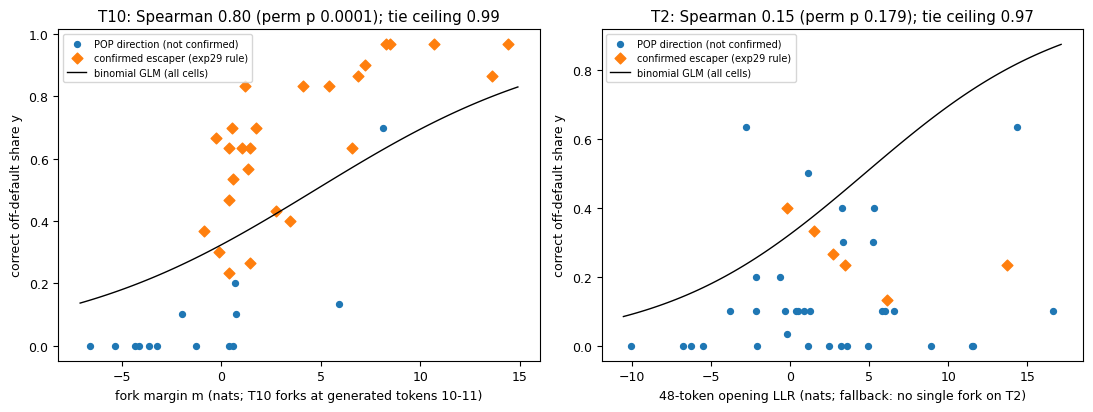

In [16]:
# ---------------------------------------------------------------------------- src/figures7.py :: f2_f3_f4 (split per figure)
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42})


def save(fig, name: str) -> None:
    fig.tight_layout()
    plt.show()  # notebook: was fig.savefig(FIGS / f"{name}.{ext}", dpi=150) for ext in png, pdf; plt.close(fig)


fa = {"F": res["F"], "cells": res["cells"]}  # notebook: was read_json(RESULTS / "f_analysis.json")
pa = {"P2": res["P2"]}                       # notebook: was read_json(RESULTS / "p2_analysis.json")
cal = fa["F"]["calibration"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, t in zip(axes, ("T10", "T2")):
    rows = fa["cells"][t]
    m = np.array([r["m"] for r in rows])
    y = np.array([r["y"] for r in rows])
    conf = np.array([r["confirmed"] for r in rows])
    ax.scatter(m[conf == 0], y[conf == 0], s=18, label="POP direction (not confirmed)")
    ax.scatter(m[conf == 1], y[conf == 1], s=30, marker="D", label="confirmed escaper (exp29 rule)")
    # notebook: cal["cells"] -> cal.get("cells", []); the 24 prompt cells are not in the curated subset
    others = [c for c in cal.get("cells", []) if c["cell"].startswith(t + "|") and "POP_" not in c["cell"]]
    for c in others:
        ax.scatter(c["m"], c["y"], marker="x", color="gray")
        ax.annotate(c["cell"].split("|")[1], (c["m"], c["y"]), fontsize=6, color="gray")
    xs = np.linspace(min(list(m) + [c["m"] for c in others]) - 0.5, max(list(m) + [c["m"] for c in others]) + 0.5,
                     100)
    ax.plot(xs, 1 / (1 + np.exp(-(cal["b0"] + cal["b1"] * xs))), "k-", lw=1, label="binomial GLM (all cells)")
    F = fa["F"][t]
    src = CELLS.get(f"{t}|TWIN", {}).get("margin_source", "")  # notebook: was read_json(c7.c3_path())["cells"]
    ax.set_title(f"{t}: Spearman {F['rho']:.2f} (perm p {F['p_perm']:.3g}); tie ceiling {F['rho_max_ties']:.2f}")
    ax.set_xlabel("fork margin m (nats; T10 forks at generated tokens 10-11)" if "llr" not in src else
                  "48-token opening LLR (nats; fallback: no single fork on T2)")
    ax.set_ylabel("correct off-default share y")
    ax.legend(fontsize=7)
save(fig, "F2_margin_vs_outcome")

### Figure F3: the axis projection beside its three competitors

Same directions, same outcome `y`. P2 predicted that the axis projection `b` (first column) would beat three competitors: the energy share in the catalogue-centroid subspace `P_t`, the raw displacement norm, and the energy share in `U4`. It does not, and none of the four predicts `y` on either task.

Look at the raw-norm panel for T10. The norm is measured at block 12, the first pushed block, and every push is norm-matched, so all 40 values lie between 13.7549 and 13.7559. That is why this notebook reads the unrounded commit #3 values. The 6-digit strings in the dataset would tie 38 of the 40 values and change this competitor's rank correlation.

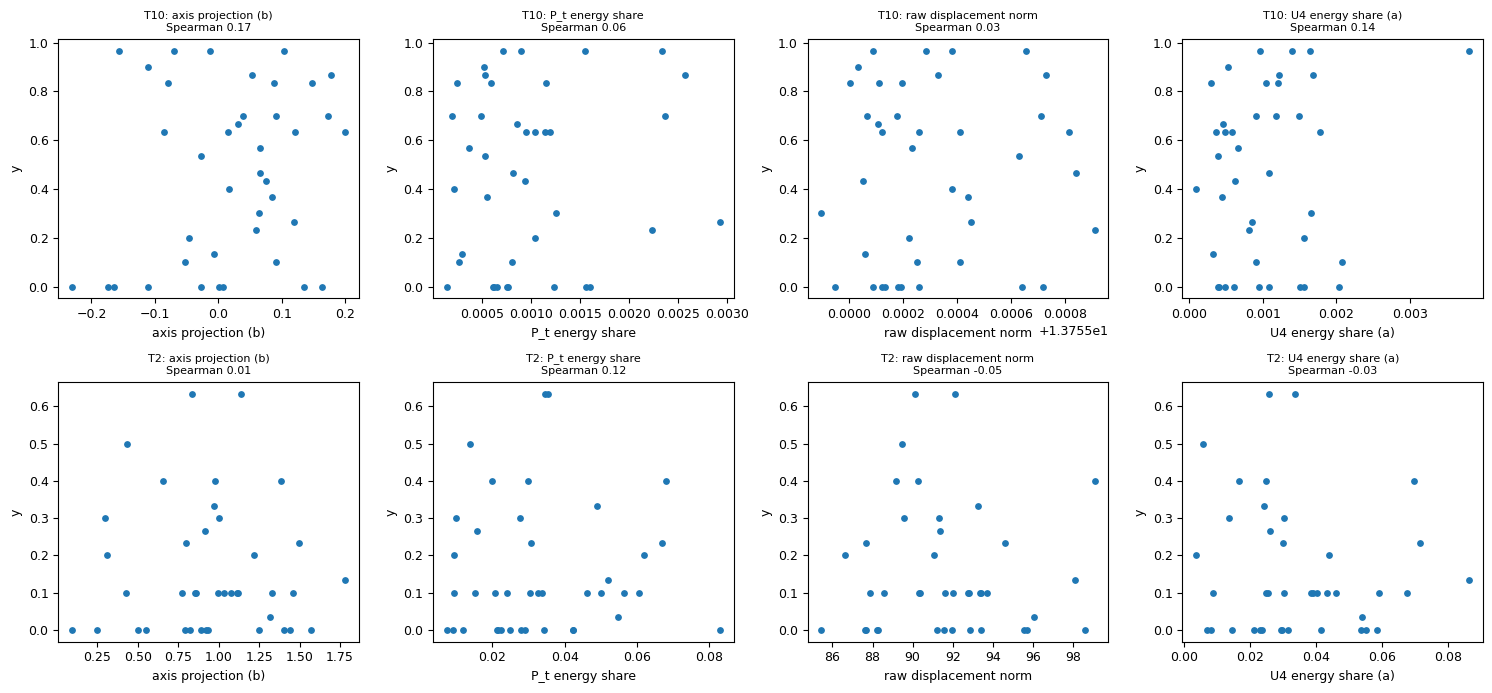

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for row, t in enumerate(("T10", "T2")):
    rows = fa["cells"][t]
    y = np.array([r["y"] for r in rows])
    for ax, (k, nm) in zip(axes[row], (("b", "axis projection (b)"), ("pi_Pt", "P_t energy share"),
                                       ("norm", "raw displacement norm"), ("a_share", "U4 energy share (a)"))):
        x = np.array([r[k] for r in rows])
        ax.scatter(x, y, s=15)
        P = pa["P2"][t]
        rho = P["rho_b"] if k == "b" else P["competitors"][k]["rho"]
        ax.set_title(f"{t}: {nm}\nSpearman {rho:.2f}", fontsize=8)
        ax.set_xlabel(nm)
        ax.set_ylabel("y")
save(fig, "F3_axis_vs_competitors")

### Figure F4: layer profile of the axis predictor

This plots the Spearman of the axis projection `(b)_L` with `y` at every captured block from 12 to 35. It is descriptive only. The pre-registered test uses `L_ax`, which was chosen without any outcome data by leave-one-out separation: block 12 for T10, block 24 for T2. No block reaches the 0.5 bar on either task. The highest values are 0.41 (T10, block 14) and 0.12 (T2, block 18).

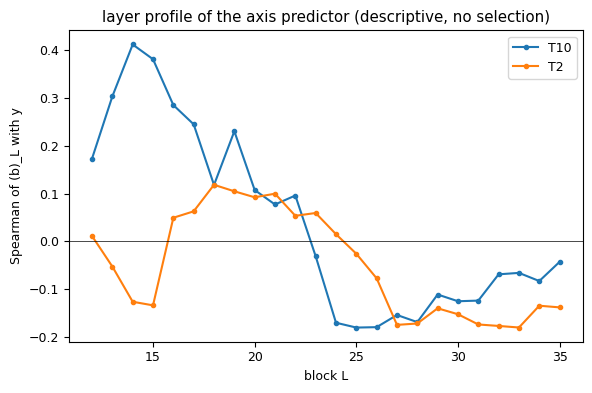

In [18]:
fig, ax = plt.subplots(figsize=(6, 4))
for t in ("T10", "T2"):
    prof = pa["P2"][t]["layer_profile"]
    L = sorted(int(k) for k in prof)
    ax.plot(L, [prof[str(l)] for l in L], "-o", ms=3, label=t)
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("block L")
ax.set_ylabel("Spearman of (b)_L with y")
ax.set_title("layer profile of the axis predictor (descriptive, no selection)")
ax.legend()
save(fig, "F4_rho_b_profile")

## What the numbers say

- **F holds on T10 and fails on T2.** On T10 the fork margin ranks the 40 random pushes by how often they produce a correct non-default algorithm. The Spearman is 0.80 (permutation p ≈ 1e-4) against a tie ceiling of 0.99. Pushes that move probability onto the off-default fork tokens at generated tokens 10-11 tend to be the ones that escape. On T2 the 48-token opening LLR does not predict escapes (0.15). T2 decides late: its only change point is near generated token 92, and in post-hoc analysis the LLR's Spearman rises to 0.42 at a 160-token opening. So the committed two-task claim is **NOT SUPPORTED (inconclusive)**: the worst-task p is 0.18 (Holm 0.36), and the committed held-out calibration MAE of 0.25 also misses the 0.10 bar.
- **P2 is disconfirmed.** The default-to-runner-up axis projection predicts neither task (0.17 and 0.01), and it does not beat any competitor. Every paired-difference CI contains 0, and none of the competitors predicts `y` either. The axis is real (neutral prompts vary along it 220-400 times more than along random directions), but random pushes do not act through it.
- **The GPU stages this notebook does not rerun** (numbers from the artifact's results):
  - Clamping the axis component out of the pushes removes no escapes (104 → 105; a random-direction clamp gives 106).
  - A push straight along the axis at 4 times the forced-prompt distance turns T10 into a correct DFS on 29/30 slots, against 0/30 for a matched random direction. The axis is a sufficient control direction, just not the channel random pushes use.
  - Forcing `' def dfs'` at tokens 10-11 under the unchanged prompt gives 30/30 correct DFS, while a comment token keeps union-find.
  - On T03 (k-th smallest) the committed opening margin prospectively predicted 24 fresh directions (Spearman 0.60, one-sided p 0.0014).
  - On T1 (grid path), pushes inside the activation manifold toward the region of algorithms outside the top five produced 0 of 300 programs outside the top five. All 300 were BFS.

**Back to the original scale.** The resampling sizes in the configuration cell are already the original ones. Regenerating the committed predictors and outcomes takes the full pipeline:
1. Clone the experiment's code.
2. Install its `pyproject.toml` into `.venv`.
3. Download `Qwen/Qwen3-8B` at revision `b968826d9c46dd6066d109eabc6255188de91218`.
4. Set `RUN_FULL_PIPELINE = True`. This is `python method.py --stages all`, about 1.7 GPU-hours on an RTX 4090.